# Can size predict age? Neural network regression

This project adapts a classroom exercise inspired by Abalone. I use simulated mollusk dimensions and mass to estimate age in years. A multilayer perceptron (MLP) with ReLU activation is compared with the training-set mean and linear regression.

Open this notebook in VS Code or Jupyter using the Python environment from the README, then run all cells. The notebook generates the demonstration data with a fixed random seed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)
n = 3000
length = rng.uniform(3, 15, n)
width_ratio = rng.uniform(0.55, 0.90, n)
width = length * width_ratio
height = length * rng.uniform(0.18, 0.32, n)
mass = 0.58 * length * width * height * rng.lognormal(0, 0.10, n)
measurements = pd.DataFrame({
    "length_cm": length, "width_cm": width,
    "height_cm": height, "mass_g": mass,
})
age = np.maximum(
    0.5, 2 + 0.042 * (length - 3) ** 2
    + 0.9 * np.sin(0.75 * length)
    + 0.85 * (width_ratio > 0.73) * (length > 9)
    + rng.normal(0, 0.45, n)
)
X_train, X_test, y_train, y_test = train_test_split(
    measurements, age, test_size=0.25, random_state=42
)

## Training and evaluation

The simulated relationship between age and measurements includes curvature, an interaction, and noise. The MLP has two hidden layers with 32 and 16 units. The pipeline fits the scaler on the training split. The MLP holds back 15% of that split for early stopping. The separate test split is used to evaluate all three models.

In [2]:
neural_network = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(32, 16), activation="relu", solver="adam",
        max_iter=600, early_stopping=True, validation_fraction=0.15,
        n_iter_no_change=25, random_state=42,
    ),
)
models = {
    "Training-set mean": DummyRegressor(),
    "Linear regression": LinearRegression(),
    "Neural network": neural_network,
}
scores = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    predictions[name] = predicted
    scores[name] = {
        "MAE (years)": mean_absolute_error(y_test, predicted),
        "RMSE (years)": np.sqrt(mean_squared_error(y_test, predicted)),
        "R²": r2_score(y_test, predicted),
    }

print(pd.DataFrame(scores).T.round(3).to_string())
print(f"Neural network training epochs: {neural_network[-1].n_iter_}")

                   MAE (years)  RMSE (years)     R²
Training-set mean        1.938         2.120 -0.001
Linear regression        0.709         0.861  0.835
Neural network           0.378         0.486  0.947
Neural network training epochs: 415


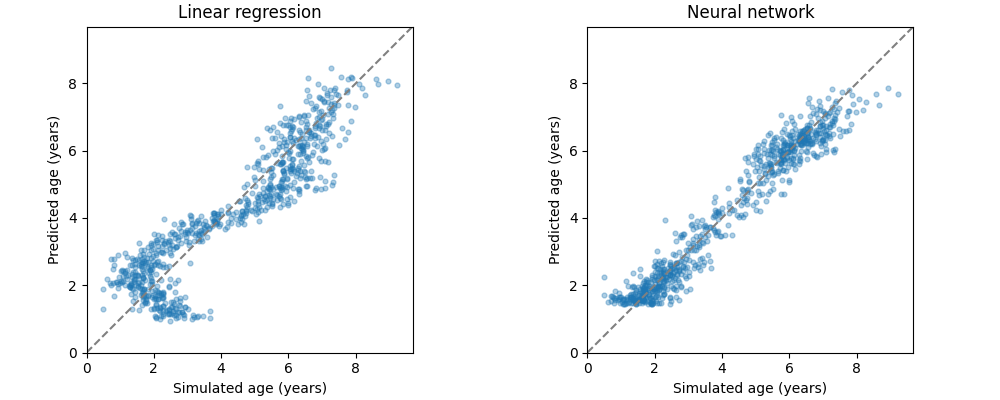

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
upper_limit = max(y_test.max(), *(v.max() for v in predictions.values())) * 1.05
lower_limit = min(0, *(v.min() for v in predictions.values()))
for ax, name in zip(axes, ["Linear regression", "Neural network"]):
    predicted = predictions[name]
    ax.scatter(y_test, predicted, s=12, alpha=0.35)
    ax.plot([lower_limit, upper_limit], [lower_limit, upper_limit], "--", color="gray")
    ax.set(
        title=name, xlabel="Simulated age (years)", ylabel="Predicted age (years)",
        xlim=(lower_limit, upper_limit), ylim=(lower_limit, upper_limit), aspect="equal"
    )
plt.show()

## Results

On this simulated test split, the MLP achieved an MAE of 0.38 years versus 0.71 years for linear regression. The plots show how predictions compare with simulated ages. The simulation favors models that can learn nonlinear relationships. Using this approach on real mollusks would require validation with observed measurements and ages.